In [1]:
what_were_covering = {1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (training)",
    4: "making predictions and evaluating a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}

# A PyTorch Workflow[cite: 1]

1. **Get data ready (turn into tensors)**[cite: 1]
2. **Build or pick a pretrained model (to suit your problem)**[cite: 1]
   * **2.1 Pick a loss function & optimizer**[cite: 1]
   * **2.2 Build a training loop**[cite: 1]
3. **Fit the model to the data and make a prediction**[cite: 1]
4. **Evaluate the model**[cite: 1]
5. **Improve through experimentation**[cite: 1]
6. **Save and reload your trained model**[cite: 1]

---

```mermaid
flowchart LR
    A["1. Get data ready\n(turn into tensors)"] --> B["2. Build or pick a pretrained model\n(to suit your problem)"]
    B --> C["2.1 Pick a loss function & optimizer"]
    C --> D["2.2 Build a training loop"]
    D --> E["3. Fit the model to the data\and make a prediction"]
    E --> F["4. Evaluate the model"]
    F --> G["5. Improve through experimentation"]
    G --> H["6. Save and reload your trained model"]

In [2]:
import torch 
from torch import nn ## nn(neural netwoks) contains all PyTorch's building blocks for neural networks 
import matplotlib.pyplot as plt 

torch.__version__


'2.14.0'

# 1. Data (preparing and loading)

#### To learn how machine learning works from scratch, we need data. If we do not have a real dataset (like photos or spreadsheets), we can simply create our own.

In [4]:
# Create a "Known" Parameters

weight = 0.7
bias = 0.3

# create a data 
X = torch.arange(start=0,end= 1,step=0.02).unsqueeze(dim=1)

".unsqueeze(dim=1): Adds an extra dimension to turn the flat list into a vertical column shape.   "
"Without it, shape is [50].    With .unsqueeze(dim=1), shape becomes [50, 1]."
"Why? PyTorch layers expect inputs formatted as [batch_size, number_of_features],"
" so each number needs its own bracket: [[0.00], [0.02], [0.04], ...]"

y = weight * X + bias

X[:10],y[:10]


(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [5]:
## Creating a Train/Test split 
train_split = int(len(X)*0.8)
X_train, y_train = X[:train_split],y[:train_split]
X_test , y_test = X[train_split:],y[train_split:]

len(X_train),len(y_train),len(X_test),len(y_test)


(40, 40, 10, 10)

In [12]:
def plot_predictions(train_data = X_train,train_labels = y_train,test_data = X_test,test_labels = y_test,Predictions = None):

    plt.Figure(figsize=(10,7))
    plt.scatter(train_data,train_labels,c="b",s=4,label = "Training Data")
    plt.scatter(test_data,test_labels,c="g",s=4,label = "Testing Data")

    if Predictions is not None :
        plt.scatter(test_data,Predictions , c = "r", s = 4 , label = "Predictions")

    plt.legend(prop={"size" : 14 })    ;

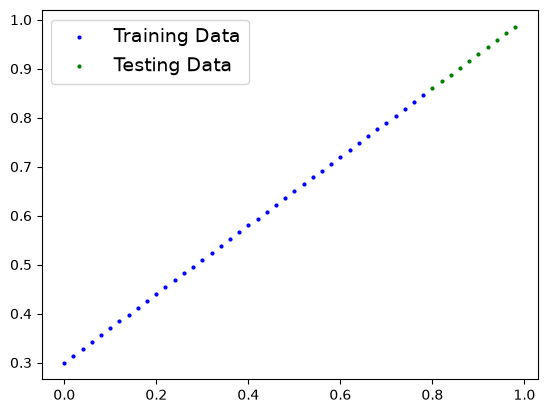

In [13]:
plot_predictions();

# 2. Build model

##### Now we've got some data, let's build a model to use the blue dots to predict the green dots.



In [14]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.parameter(torch.rand(1,dtype=torch.float),requires_grad_=True)
        self.bias = nn.parameter(torch.randn(1,dtype=torch.float),requires_grad_= True)

    def forward(self,x:torch.Tensor) -> torch.tensor:
        return self.weights*x + self.bias    

## PyTorch model building essentials
### * PyTorch has four (give or take) essential modules you can use to create almost any kind of neural network you can imagine.
#### They are "torch.nn", "torch.optim", "torch.utils.data.Dataset" and "torch.utils.data.DataLoader". For now, we'll focus on the first two and get to the other two later (though you may be able to guess what they do).

* almost everything in a PyTorch neural network comes from "torch.nn".

* "nn.Module" contains the larger building blocks (layers)
* "nn.Parameter" contains the smaller parameters like weights and biases (put these together to make nn.Module(s))
* "forward()" tells the larger blocks how to make calculations on inputs (tensors full of data) within nn.Module(s)
* "torch.optim" contains optimization methods on how to improve the parameters within nn.Parameter to better represent input data